   CGPA  Resume_Score  Placement
0   9.2            90          1
1   8.5            85          1
2   7.8            80          1
3   6.5            75          1
4   5.5            40          0
5   6.0            45          0
6   5.0            50          0
7   4.5            30          0
8   7.0            60          1
9   5.8            55          0

--- Perceptron Values ---
Weights: [[1.03127498 1.28416374]]
Bias: [0.]

Actual Values: [1 1 1 1 0 0 0 0 1 0]
Predicted Values: [1 1 1 1 0 0 0 0 1 0]
Accuracy: 1.0

--- New Student ---
CGPA: 8.0
Resume Score: 78
Perceptron Value: 2.128178611355973
Prediction: PLACED


d:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


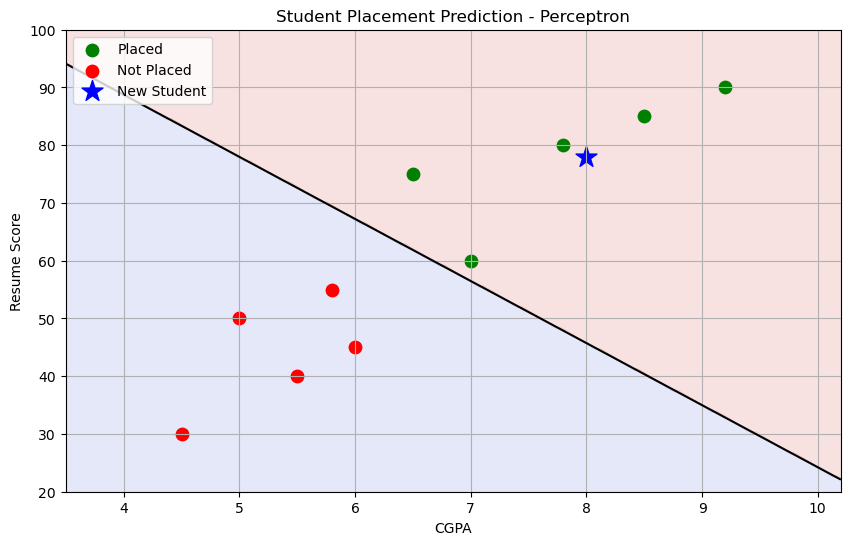

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler

# 1. Create dataset
data = {
    "CGPA": [9.2, 8.5, 7.8, 6.5, 5.5,
             6.0, 5.0, 4.5, 7.0, 5.8],

    "Resume_Score": [90, 85, 80, 75, 40,
                     45, 50, 30, 60, 55],

    "Placement": [1, 1, 1, 1, 0,
                  0, 0, 0, 1, 0]
}

df = pd.DataFrame(data)
print(df)

# 2. Split X and y
X = df[["CGPA", "Resume_Score"]]
y = df["Placement"]

# 3. Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Create perceptron
model = Perceptron(max_iter=1000, random_state=42)

# 5. Train model
model.fit(X_scaled, y)

# 6. Print perceptron values
print("\n--- Perceptron Values ---")
print("Weights:", model.coef_)
print("Bias:", model.intercept_)

# 7. Prediction
pred = model.predict(X_scaled)

print("\nActual Values:", y.values)
print("Predicted Values:", pred)
print("Accuracy:", model.score(X_scaled, y))

# 8. New student prediction
new_student = [[8.0, 78]]

new_scaled = scaler.transform(new_student)

result = model.predict(new_scaled)
decision_value = model.decision_function(new_scaled)

print("\n--- New Student ---")
print("CGPA:", new_student[0][0])
print("Resume Score:", new_student[0][1])
print("Perceptron Value:", decision_value[0])

if result[0] == 1:
    print("Prediction: PLACED")
else:
    print("Prediction: NOT PLACED")

# 9. Create decision boundary
x_min, x_max = X["CGPA"].min()-1, X["CGPA"].max()+1
y_min, y_max = X["Resume_Score"].min()-10, X["Resume_Score"].max()+10

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)

Z = model.predict(grid_scaled)
Z = Z.reshape(xx.shape)

# 10. Plot graph
plt.figure(figsize=(10, 6))

plt.contourf(xx, yy, Z, alpha=0.15, cmap="coolwarm")

plt.scatter(
    X["CGPA"][y == 1],
    X["Resume_Score"][y == 1],
    color="green",
    label="Placed",
    s=80
)

plt.scatter(
    X["CGPA"][y == 0],
    X["Resume_Score"][y == 0],
    color="red",
    label="Not Placed",
    s=80
)

plt.scatter(
    new_student[0][0],
    new_student[0][1],
    color="blue",
    marker="*",
    s=250,
    label="New Student"
)

plt.contour(
    xx, yy, 
    model.decision_function(grid_scaled).reshape(xx.shape),
    levels=[0],
    colors="black"
)

plt.xlabel("CGPA")
plt.ylabel("Resume Score")
plt.title("Student Placement Prediction - Perceptron")
plt.legend()
plt.grid(True)
plt.show()
